# TALLER I – ANÁLISIS DE GRANDES VOLÚMENES DE DATOS

# Grupo 4

## Integrantes:
#### Matias Almonacid
#### Carolina Castro

**Parte I**

## 1. Configuración inicial del entorno

Primero preparamos el entorno y comprobamos que Spark se pueda iniciar. Después usamos esa sesión durante el resto del taller.

### 1.1. Importaciones

Importamos las librerías que vamos a usar. SparkSession permite iniciar Spark; col y las funciones de PySpark sirven para trabajar con las columnas. También usamos os y shutil para configurar Java.

In [39]:
import os
import shutil

#!pip install -q pyspark

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
from pyspark.sql import functions as F

### 1.2. Configuración de Java

Buscamos dónde está instalado Java y usamos esa ubicación para definir JAVA_HOME. Agregamos su carpeta bin al PATH para que Spark pueda encontrar el ejecutable al iniciar.

In [2]:
java_path = os.path.realpath(shutil.which("java"))
JAVA_HOME = os.path.dirname(os.path.dirname(java_path))

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["PATH"] = os.path.join(JAVA_HOME, "bin") + os.pathsep + os.environ["PATH"]

print("JAVA_HOME:", os.environ["JAVA_HOME"])

JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64


### 1.3. Creación de la sesión de Spark

Creamos una sesión de Spark para trabajar en el computador. La opción local[*] usa los núcleos disponibles. Desde la sesión obtenemos el SparkContext, que utilizamos después para crear los RDD.

In [3]:
spark = (
    SparkSession.builder
    .appName("Taller_Grandes_Volumenes_Datos")
    .master("local[*]")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("ERROR")

26/10/03 15:03:09 WARN Utils: Your hostname, caro resolves to a loopback address: 127.0.1.1; using 172.20.10.4 instead (on interface wlp0s20f3)
26/10/03 15:03:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/03 15:03:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### 1.4. Revisión de la sesión

Mostramos la versión de Spark y comprobamos que se hayan creado la sesión y el contexto. Esta revisión nos permite confirmar que el entorno está listo antes de leer los datos.

In [4]:
print("Spark version:", spark.version)
print("SparkSession creada:", spark)
print("SparkContext:", sc)

Spark version: 3.5.8
SparkSession creada: <pyspark.sql.session.SparkSession object at 0x786fa2f34950>
SparkContext: <SparkContext master=local[*] appName=Taller_Grandes_Volumenes_Datos>


## 2. RDDs: creación y unión

Los deportistas vienen repartidos en dos archivos. Los cargamos como RDD, unimos sus registros y revisamos la estructura antes de trabajar con columnas.

### 2.1. Lectura de los archivos de deportistas

Leemos deportista.csv y deportista2.csv como archivos de texto. Cada línea queda como un registro del RDD. Para el primer archivo pedimos al menos seis particiones y revisamos cuántas tiene cada RDD.

In [5]:
deportista = sc.textFile("deportista.csv", minPartitions=6)
deportista2 = sc.textFile("deportista2.csv")

print("Particiones de deportista:", deportista.getNumPartitions())
print("Particiones de deportista2:", deportista2.getNumPartitions())

Particiones de deportista: 6
Particiones de deportista2: 2


### 2.2. Primeros registros

Mostramos cinco registros de cada archivo para revisar su formato. Aquí se pueden reconocer los identificadores, los nombres y las medidas de los deportistas antes de separar las columnas.

In [6]:
print("Primeros registros de deportista:")
for fila in deportista.take(5):
    print(fila)

print("\nPrimeros registros de deportista 2:")
for fila in deportista2.take(5):
    print(fila)

Primeros registros de deportista:


1,A Dijiang,1,24,180,80,199
2,A Lamusi,1,23,170,60,199
3,Gunnar Nielsen Aaby,1,24,0,0,273
4,Edgar Lindenau Aabye,1,34,0,0,278
5,Christine Jacoba Aaftink,2,21,185,82,705

Primeros registros de deportista 2:
67787,Lee BongJu,1,27,167,56,970
67788,Lee BuTi,1,23,164,54,203
67789,Anthony N. Buddy Lee,1,34,172,62,1096
67790,Alfred A. Butch Lee Porter,1,19,186,80,825
67791,Lee ByeongGu,1,22,175,68,970


### 2.3. Unión de los dos RDD

Unimos los dos RDD con union y contamos el resultado. La unión conserva los registros de ambos archivos; no elimina duplicados por sí sola. El catálogo unido contiene 135.571 filas.

In [7]:
deportistaTotal = deportista.union(deportista2)

print("Cantidad de registros en deportistaTotal:", deportistaTotal.count())

Cantidad de registros en deportistaTotal: 135571


### 2.4. Separación de los campos

Separamos cada línea usando la coma. Así pasamos de una cadena de texto a una lista de campos y podemos acceder a la edad, al género y a las otras variables por su posición.

In [8]:
deportistaTotal_split = deportistaTotal.map(lambda x: x.split(","))

### 2.5. Creación del DataFrame de deportistas

Asignamos los siete nombres de columnas y creamos el DataFrame de deportistas. Mostramos algunas filas para revisar que los valores hayan quedado en la columna que corresponde.

In [9]:
columnas = [
    "deportista_id",
    "nombre",
    "genero",
    "edad",
    "altura",
    "peso",
    "equipo_id"
]

deportista = deportistaTotal_split.toDF(columnas)

deportista.show(10)

+-------------+--------------------+------+----+------+----+---------+
|deportista_id|              nombre|genero|edad|altura|peso|equipo_id|
+-------------+--------------------+------+----+------+----+---------+
|            1|           A Dijiang|     1|  24|   180|  80|      199|
|            2|            A Lamusi|     1|  23|   170|  60|      199|
|            3| Gunnar Nielsen Aaby|     1|  24|     0|   0|      273|
|            4|Edgar Lindenau Aabye|     1|  34|     0|   0|      278|
|            5|Christine Jacoba ...|     2|  21|   185|  82|      705|
|            6|     Per Knut Aaland|     1|  31|   188|  75|     1096|
|            7|        John Aalberg|     1|  31|   183|  72|     1096|
|            8|Cornelia Cor Aalt...|     2|  18|   168|   0|      705|
|            9|    Antti Sami Aalto|     1|  26|   186|  96|      350|
|           10|Einar Ferdinand E...|     1|  26|     0|   0|      350|
+-------------+--------------------+------+----+------+----+---------+
only s

### 2.6. Conversión de las columnas numéricas

Al crear el DataFrame desde el RDD, las columnas quedan inicialmente como texto. Convertimos los identificadores, el género y la edad a enteros, y la altura y el peso a decimales. Esto permite hacer filtros y cálculos con esas variables.

In [10]:
deportista = (
    deportistaTotal_split
    .toDF(columnas)
    .withColumn("deportista_id", col("deportista_id").cast("int"))
    .withColumn("genero", col("genero").cast("int"))
    .withColumn("edad", col("edad").cast("int"))
    .withColumn("altura", col("altura").cast("double"))
    .withColumn("peso", col("peso").cast("double"))
    .withColumn("equipo_id", col("equipo_id").cast("int"))
)

deportista.show(10)
deportista.printSchema()

+-------------+--------------------+------+----+------+----+---------+
|deportista_id|              nombre|genero|edad|altura|peso|equipo_id|
+-------------+--------------------+------+----+------+----+---------+
|            1|           A Dijiang|     1|  24| 180.0|80.0|      199|
|            2|            A Lamusi|     1|  23| 170.0|60.0|      199|
|            3| Gunnar Nielsen Aaby|     1|  24|   0.0| 0.0|      273|
|            4|Edgar Lindenau Aabye|     1|  34|   0.0| 0.0|      278|
|            5|Christine Jacoba ...|     2|  21| 185.0|82.0|      705|
|            6|     Per Knut Aaland|     1|  31| 188.0|75.0|     1096|
|            7|        John Aalberg|     1|  31| 183.0|72.0|     1096|
|            8|Cornelia Cor Aalt...|     2|  18| 168.0| 0.0|      705|
|            9|    Antti Sami Aalto|     1|  26| 186.0|96.0|      350|
|           10|Einar Ferdinand E...|     1|  26|   0.0| 0.0|      350|
+-------------+--------------------+------+----+------+----+---------+
only s

## 3. RDDs: transformaciones 

Aplicamos las transformaciones solicitadas al RDD: filtros por edad y género, y conversión del texto a mayúsculas.

### 3.1. Preparación del RDD

Preparamos un RDD con los campos separados. Usamos este RDD para los filtros de edad y género que se piden en el taller.

In [11]:
deportista_split = deportistaTotal.map(lambda x: x.split(","))

### 3.2. Deportistas mayores de edad

Filtramos los registros cuya edad es mayor o igual a 18. La edad está en la cuarta posición de cada fila, por eso usamos el índice 3 y convertimos el valor a entero antes de compararlo.

In [12]:
# Filtramos deportistas mayores de edad (18 años o más)
MayorEdad = deportista_split.filter(lambda x: int(x[3]) >= 18)

print("Deportistas mayores de edad:")
for fila in MayorEdad.take(10):
    print(fila)

Deportistas mayores de edad:
['1', 'A Dijiang', '1', '24', '180', '80', '199']
['2', 'A Lamusi', '1', '23', '170', '60', '199']
['3', 'Gunnar Nielsen Aaby', '1', '24', '0', '0', '273']
['4', 'Edgar Lindenau Aabye', '1', '34', '0', '0', '278']
['5', 'Christine Jacoba Aaftink', '2', '21', '185', '82', '705']
['6', 'Per Knut Aaland', '1', '31', '188', '75', '1096']
['7', 'John Aalberg', '1', '31', '183', '72', '1096']
['8', 'Cornelia Cor Aalten Strannood ', '2', '18', '168', '0', '705']
['9', 'Antti Sami Aalto', '1', '26', '186', '96', '350']
['10', 'Einar Ferdinand Einari Aalto', '1', '26', '0', '0', '350']


### 3.3. Deportistas mujeres

Seleccionamos los registros con género igual a 2, que corresponde a mujer en los datos del taller. Mostramos diez filas para revisar el filtro.

In [13]:
# Filtramos deportistas de género femenino.
# Según la pauta, genero = 2 corresponde a mujer.
Deportistas_mujer = deportista_split.filter(lambda x: int(x[2]) == 2)

print("Deportistas mujeres:")
for fila in Deportistas_mujer.take(10):
    print(fila)

Deportistas mujeres:
['5', 'Christine Jacoba Aaftink', '2', '21', '185', '82', '705']
['8', 'Cornelia Cor Aalten Strannood ', '2', '18', '168', '0', '705']
['13', 'Minna Maarit Aalto', '2', '30', '159', '55.5', '350']
['14', 'Pirjo Hannele Aalto Mattila ', '2', '32', '171', '65', '350']
['21', 'Ragnhild Margrethe Aamodt', '2', '27', '163', '0', '742']
['22', 'Andreea Aanei', '2', '22', '170', '125', '861']
['26', 'Agnes Erika Aanonsen Eyde ', '2', '17', '169', '65', '742']
['29', 'Willemien Aardenburg', '2', '22', '0', '0', '705']
['37', 'Ann Kristin Aarnes', '2', '23', '182', '64', '742']
['49', 'Moonika Aava', '2', '24', '168', '65', '331']


### 3.4. Conversión a mayúsculas

Aplicamos upper a cada línea del RDD unido. Esta transformación deja todo el texto en mayúsculas y conserva la cantidad de registros.

In [14]:
# Convertimos todo el contenido del RDD deportistaTotal a mayúsculas
deportistaTotal_mayusculas = deportistaTotal.map(lambda x: x.upper())

print("Contenido en mayúsculas:")
for fila in deportistaTotal_mayusculas.take(10):
    print(fila)

Contenido en mayúsculas:
1,A DIJIANG,1,24,180,80,199
2,A LAMUSI,1,23,170,60,199
3,GUNNAR NIELSEN AABY,1,24,0,0,273
4,EDGAR LINDENAU AABYE,1,34,0,0,278
5,CHRISTINE JACOBA AAFTINK,2,21,185,82,705
6,PER KNUT AALAND,1,31,188,75,1096
7,JOHN AALBERG,1,31,183,72,1096
8,CORNELIA COR AALTEN STRANNOOD ,2,18,168,0,705
9,ANTTI SAMI AALTO,1,26,186,96,350
10,EINAR FERDINAND EINARI AALTO,1,26,0,0,350


## 4. DataFrames: creación e integración

Cargamos las otras fuentes, revisamos los problemas encontrados en la lectura y unimos la información mediante sus identificadores.

### 4.1. Carga de los archivos

Cargamos los archivos de eventos, resultados y equipos como CSV, y las ediciones como JSON. Indicamos que los CSV tienen encabezado y dejamos que Spark reconozca los tipos de datos. Después mostramos algunas filas de cada fuente.

In [15]:
Evento = spark.read.csv("evento.csv", header=True, inferSchema=True)
Resultado = spark.read.csv("resultados.csv", header=True, inferSchema=True, sep=",")
Equipos = spark.read.csv("equipo.csv", header=True, inferSchema=True)
Juego = spark.read.option("multiline", "true").json("juegos.json")
Juego = Juego.toDF("año", "ciudad", "juego_id", "temporada")

In [16]:
Evento.show(5)
Resultado.show(5)
Equipos.show(5)
Juego.show(5)

+----------+--------------------+----------+
|cod_evento|              evento|deporte_id|
+----------+--------------------+----------+
|         1|Basketball Men's ...|         1|
|         2|Judo Men's Extra-...|         2|
|         3|Football Men's Fo...|         3|
|         4|Tug-Of-War Men's ...|         4|
|         5|Speed Skating Wom...|         5|
+----------+--------------------+----------+
only showing top 5 rows

+-----------------------------------------------------+
|resultado_id;medalla;deportista_id;juego_id;evento_id|
+-----------------------------------------------------+
|                                          1;NA;1;39;1|
|                                          2;NA;2;49;2|
|                                           3;NA;3;7;3|
|                                         4;Gold;4;2;4|
|                                          5;NA;5;36;5|
+-----------------------------------------------------+
only showing top 5 rows

+---+--------------------+-----+
| id|   

### 4.2. Corrección del separador de resultados

Al revisar Resultado, vimos que todas las columnas habían quedado juntas. El archivo resultados.csv usa punto y coma como separador. Lo volvemos a leer con sep=";" y comprobamos que ahora se distingan resultado_id, medalla, deportista_id, juego_id y evento_id.

In [17]:
Resultado = spark.read.csv(
    "resultados.csv",
    header=True,
    inferSchema=True,
    sep=";"
)

Resultado.show(5)

+------------+-------+-------------+--------+---------+
|resultado_id|medalla|deportista_id|juego_id|evento_id|
+------------+-------+-------------+--------+---------+
|           1|     NA|            1|      39|        1|
|           2|     NA|            2|      49|        2|
|           3|     NA|            3|       7|        3|
|           4|   Gold|            4|       2|        4|
|           5|     NA|            5|      36|        5|
+------------+-------+-------------+--------+---------+
only showing top 5 rows



### 4.3. Revisión de juegos.json

Revisamos el esquema y los primeros registros para comprobar qué contiene cada columna. Después de la lectura, año contiene textos como 1896 Verano; temporada contiene el año numérico, y ciudad contiene Verano o Invierno.

Ajustamos los nombres para que coincidan con esos valores:

| Columna después de la lectura | Nombre final | Qué representa |
| --- | --- | --- |
| año | edicion | Año y temporada en un mismo texto. |
| temporada | año | Año numérico de la edición. |
| ciudad | temporada | Verano o Invierno. |

El archivo no trae la ciudad sede, así que no agregamos esa información.

In [18]:
Juego.printSchema()
Juego.show(10, truncate=False)

root
 |-- año: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- juego_id: long (nullable = true)
 |-- temporada: long (nullable = true)

+-------------+--------+--------+---------+
|año          |ciudad  |juego_id|temporada|
+-------------+--------+--------+---------+
|1896 Verano  |Verano  |1       |1896     |
|1900 Verano  |Verano  |2       |1900     |
|1904 Verano  |Verano  |3       |1904     |
|1906 Verano  |Verano  |4       |1906     |
|1908 Verano  |Verano  |5       |1908     |
|1912 Verano  |Verano  |6       |1912     |
|1920 Verano  |Verano  |7       |1920     |
|1924 Invierno|Invierno|8       |1924     |
|1924 Verano  |Verano  |9       |1924     |
|1928 Invierno|Invierno|10      |1928     |
+-------------+--------+--------+---------+
only showing top 10 rows



In [19]:
import json

filas_juegos = [fila.asDict() for fila in Juego.take(10)]
contenido = json.dumps(filas_juegos, ensure_ascii=False, indent=2)
print(contenido[:1000])

[
  {
    "año": "1896 Verano",
    "ciudad": "Verano",
    "juego_id": 1,
    "temporada": 1896
  },
  {
    "año": "1900 Verano",
    "ciudad": "Verano",
    "juego_id": 2,
    "temporada": 1900
  },
  {
    "año": "1904 Verano",
    "ciudad": "Verano",
    "juego_id": 3,
    "temporada": 1904
  },
  {
    "año": "1906 Verano",
    "ciudad": "Verano",
    "juego_id": 4,
    "temporada": 1906
  },
  {
    "año": "1908 Verano",
    "ciudad": "Verano",
    "juego_id": 5,
    "temporada": 1908
  },
  {
    "año": "1912 Verano",
    "ciudad": "Verano",
    "juego_id": 6,
    "temporada": 1912
  },
  {
    "año": "1920 Verano",
    "ciudad": "Verano",
    "juego_id": 7,
    "temporada": 1920
  },
  {
    "año": "1924 Invierno",
    "ciudad": "Invierno",
    "juego_id": 8,
    "temporada": 1924
  },
  {
    "año": "1924 Verano",
    "ciudad": "Verano",
    "juego_id": 9,
    "temporada": 1924
  },
  {
    "año": "1928 Invierno",
    "ciudad": "Invierno",
    "juego_id": 10,
    "temporada":

In [20]:
Juego_original = Juego

Juego = (
    Juego_original
    .withColumnRenamed("año", "edicion")
    .withColumnRenamed("temporada", "año")
    .withColumnRenamed("ciudad", "temporada")
)

In [21]:
Juego.show(10, truncate=False)
Juego.printSchema()

+-------------+---------+--------+----+
|edicion      |temporada|juego_id|año |
+-------------+---------+--------+----+
|1896 Verano  |Verano   |1       |1896|
|1900 Verano  |Verano   |2       |1900|
|1904 Verano  |Verano   |3       |1904|
|1906 Verano  |Verano   |4       |1906|
|1908 Verano  |Verano   |5       |1908|
|1912 Verano  |Verano   |6       |1912|
|1920 Verano  |Verano   |7       |1920|
|1924 Invierno|Invierno |8       |1924|
|1924 Verano  |Verano   |9       |1924|
|1928 Invierno|Invierno |10      |1928|
+-------------+---------+--------+----+
only showing top 10 rows

root
 |-- edicion: string (nullable = true)
 |-- temporada: string (nullable = true)
 |-- juego_id: long (nullable = true)
 |-- año: long (nullable = true)



### 4.4. Revisión de las columnas

Mostramos los nombres de columnas de cada DataFrame. Esta revisión ayuda a identificar las claves que vamos a usar en las uniones y a evitar confundir columnas con nombres parecidos.

In [22]:
print("Evento:", Evento.columns)
print("Resultado:", Resultado.columns)
print("Equipos:", Equipos.columns)
print("Juego:", Juego.columns)

Evento: ['cod_evento', 'evento', 'deporte_id']
Resultado: ['resultado_id', 'medalla', 'deportista_id', 'juego_id', 'evento_id']
Equipos: ['id', 'equipo', 'sigla']
Juego: ['edicion', 'temporada', 'juego_id', 'año']


### 4.5. Revisión de la cantidad de campos

El archivo de deportistas debería tener siete campos por fila. Filtramos las filas que tienen una cantidad distinta y mostramos los registros encontrados para revisar qué ocurrió.

In [23]:
# Revisamos cuántos elementos tiene cada registro
filas_incorrectas = deportistaTotal_split.filter(lambda x: len(x) != 7)

print("Cantidad de filas con número de columnas distinto de 7:")
print(filas_incorrectas.count())
print(filas_incorrectas.take(135571))

Cantidad de filas con número de columnas distinto de 7:
1
[['16587', 'Vladimr Bil', '1', '24', '191', '92', '67', '']]


### 4.6. Corrección de la fila de deportistas

Usamos csv.reader para separar los campos respetando el formato CSV. Si una fila trae ocho campos y el último está vacío, quitamos ese campo adicional. Aplicamos la función al RDD y dejamos listas las filas para reconstruir el DataFrame.

In [25]:
import csv

# Se utiliza csv.reader para interpretar correctamente las filas CSV
# y corregir registros que contienen una columna vacía adicional.

def corregir_fila(linea):
    datos = next(csv.reader([linea]))

    # Si existe una columna vacía adicional al final,
    # se elimina para mantener las 7 columnas esperadas.
    if len(datos) == 8 and datos[-1] == "":
        datos = datos[:-1]

    return datos

deportistaTotal_split = deportistaTotal.map(corregir_fila)

### 4.7. Caché de los DataFrames

Guardamos en caché los DataFrames que vamos a reutilizar. Después los contamos para que Spark ejecute la lectura y materialice la caché. Esto evita repetir toda la carga en cada operación posterior.

In [26]:
# Optimización de los DataFrames mediante cache

Evento.cache()
Resultado.cache()
Equipos.cache()
Juego.cache()
#deportista.cache()

# Materializamos la caché para que efectivamente se aplique
print("Registros Evento:", Evento.count())
print("Registros Resultado:", Resultado.count())
print("Registros Equipos:", Equipos.count())
print("Registros Juego:", Juego.count())
#print("Registros Deportista:", deportista.count())

Registros Evento: 765


Registros Resultado: 271116
Registros Equipos: 1184
Registros Juego: 51


### 4.8. Revisión de la caché de deportistas

Al intentar guardar deportista en caché apareció un problema con una fila que tenía una coma adicional al final. Esa coma producía un octavo campo vacío, mientras que el esquema esperaba siete. Después de corregir la fila, reconstruimos el DataFrame y volvemos a aplicar la caché.

### 4.9. Comprobación de las filas corregidas

Repetimos el filtro de cantidad de campos sobre el RDD corregido. El conteo y la muestra permiten comprobar si todavía queda alguna fila que no tenga los siete campos esperados.

In [27]:
filas_incorrectas = deportistaTotal_split.filter(lambda x: len(x) != 7)

print("Filas incorrectas:", filas_incorrectas.count())
print(filas_incorrectas.take(10))

Filas incorrectas: 0
[]


### 4.10. Reconstrucción del DataFrame de deportistas

Creamos nuevamente el DataFrame usando las filas corregidas y convertimos las columnas numéricas. Revisamos una muestra, el esquema y la cantidad de registros. Al final guardamos deportista en caché para reutilizarlo en la integración.

In [28]:
columnas = [
    "deportista_id",
    "nombre",
    "genero",
    "edad",
    "altura",
    "peso",
    "equipo_id"
]

deportista = deportistaTotal_split.toDF(columnas)

In [29]:
from pyspark.sql.functions import col

deportista = (
    deportista
    .withColumn("deportista_id", col("deportista_id").cast("int"))
    .withColumn("genero", col("genero").cast("int"))
    .withColumn("edad", col("edad").cast("int"))
    .withColumn("altura", col("altura").cast("double"))
    .withColumn("peso", col("peso").cast("double"))
    .withColumn("equipo_id", col("equipo_id").cast("int"))
)

In [30]:
deportista.show(10)
deportista.printSchema()
print("Registros Deportista:", deportista.count())

+-------------+--------------------+------+----+------+----+---------+
|deportista_id|              nombre|genero|edad|altura|peso|equipo_id|
+-------------+--------------------+------+----+------+----+---------+
|            1|           A Dijiang|     1|  24| 180.0|80.0|      199|
|            2|            A Lamusi|     1|  23| 170.0|60.0|      199|
|            3| Gunnar Nielsen Aaby|     1|  24|   0.0| 0.0|      273|
|            4|Edgar Lindenau Aabye|     1|  34|   0.0| 0.0|      278|
|            5|Christine Jacoba ...|     2|  21| 185.0|82.0|      705|
|            6|     Per Knut Aaland|     1|  31| 188.0|75.0|     1096|
|            7|        John Aalberg|     1|  31| 183.0|72.0|     1096|
|            8|Cornelia Cor Aalt...|     2|  18| 168.0| 0.0|      705|
|            9|    Antti Sami Aalto|     1|  26| 186.0|96.0|      350|
|           10|Einar Ferdinand E...|     1|  26|   0.0| 0.0|      350|
+-------------+--------------------+------+----+------+----+---------+
only s

Registros Deportista: 135571


In [31]:
deportista.cache()
print("Registros Deportista:", deportista.count())

Registros Deportista: 135571


### 4.11. Integración de los DataFrames

Tomamos Resultado como punto de partida y relacionamos cada participación con su deportista, equipo, evento y edición. Los alias permiten identificar de qué tabla viene cada columna.

Las claves usadas son:

- Resultado.deportista_id con deportista.deportista_id.
- deportista.equipo_id con Equipos.id.
- Resultado.evento_id con Evento.cod_evento.
- Resultado.juego_id con Juego.juego_id.

La primera unión es interna. Las otras son izquierdas, por lo que mantienen la participación aunque falte información en una tabla relacionada. Después seleccionamos las columnas que usaremos en el análisis.

In [32]:
# Se crean alias para facilitar la identificación de cada DataFrame
d = deportista.alias("d")
r = Resultado.alias("r")
eq = Equipos.alias("eq")
ev = Evento.alias("ev")
j = Juego.alias("j")

# Integración de los DataFrames mediante sus claves relacionadas
df_integrado = (
    r
    .join(
        d,
        r.deportista_id == d.deportista_id,
        "inner"
    )
    .join(
        eq,
        d.equipo_id == eq.id,
        "left"
    )
    .join(
        ev,
        r.evento_id == ev.cod_evento,
        "left"
    )
    .join(
        j,
        r.juego_id == j.juego_id,
        "left"
    )
)

In [61]:
df_integrado = df_integrado.select(
    "r.resultado_id",
    "r.medalla",
    "d.deportista_id",
    "d.nombre",
    "d.genero",
    "d.edad",
    "d.altura",
    "d.peso",
    "d.equipo_id",
    "eq.equipo",
    "eq.sigla",
    "ev.cod_evento",
    "ev.evento",
    "ev.deporte_id",
    "j.juego_id",
    "j.edicion",
    "j.temporada",
    "j.año"
)

In [62]:
print(
    "Cantidad de registros del DataFrame integrado:",
    df_integrado.count()
)

Cantidad de registros del DataFrame integrado: 271116


### 4.12. Resultado de la integración

El conteo de la integración es de 271.116 participaciones. Una persona puede aparecer varias veces si compitió en distintos eventos o ediciones. Por eso este total es mayor que la cantidad de deportistas del catálogo.

## 5. Paralelismo

Distribuimos el DataFrame integrado en cinco particiones y comprobamos el resultado.

### 5.1. Repartición en cinco particiones

Repartimos el DataFrame integrado en cinco particiones. Luego consultamos getNumPartitions para comprobar que se haya aplicado la repartición solicitada.

In [35]:
# Repartición del DataFrame integrado en 5 particiones
df_integrado = df_integrado.repartition(5)

# Verificación del número de particiones
print(
    "Número de particiones del DataFrame integrado:",
    df_integrado.rdd.getNumPartitions()
)

Número de particiones del DataFrame integrado: 5


### 5.2. Resultado

La salida muestra cinco particiones. Con esta distribución continuamos las operaciones sobre la tabla integrada.

## 6. Inspección del DataFrame

Antes de seguir con los cálculos, revisamos el tamaño de la tabla y cómo quedaron sus columnas.

### 6.1. Cantidad de filas, tipos y esquema

Revisamos tres cosas: la cantidad de filas, los tipos de las columnas y el esquema. El conteo describe el tamaño de la tabla; dtypes y printSchema permiten revisar cómo Spark interpreta cada variable.

In [36]:
# Cantidad de filas
print("Cantidad de filas:", df_integrado.count())

# Tipos de datos
print("\nTipos de datos:")
for columna, tipo in df_integrado.dtypes:
    print(f"{columna}: {tipo}")

# Esquema del DataFrame
print("\nEsquema del DataFrame:")
df_integrado.printSchema()

Cantidad de filas: 271116

Tipos de datos:
resultado_id: int
medalla: string
deportista_id: int
juego_id: int
evento_id: string
deportista_id: int
nombre: string
genero: int
edad: int
altura: double
peso: double
equipo_id: int
id: int
equipo: string
sigla: string
cod_evento: string
evento: string
deporte_id: string
edicion: string
temporada: string
juego_id: bigint
año: bigint

Esquema del DataFrame:
root
 |-- resultado_id: integer (nullable = true)
 |-- medalla: string (nullable = true)
 |-- deportista_id: integer (nullable = true)
 |-- juego_id: integer (nullable = true)
 |-- evento_id: string (nullable = true)
 |-- deportista_id: integer (nullable = true)
 |-- nombre: string (nullable = true)
 |-- genero: integer (nullable = true)
 |-- edad: integer (nullable = true)
 |-- altura: double (nullable = true)
 |-- peso: double (nullable = true)
 |-- equipo_id: integer (nullable = true)
 |-- id: integer (nullable = true)
 |-- equipo: string (nullable = true)
 |-- sigla: string (nullable =

### 6.2. Resultado

El conteo muestra 271.116 filas. Los identificadores permiten relacionar los datos, mientras que edad, altura y peso se utilizan en los cálculos. También revisamos las columnas de texto, como equipo, evento y temporada.

## 7. Columnas calculadas

Agregamos el IMC y una descripción del sexo a partir de las columnas que ya están en el DataFrame.

### 7.1. Cálculo del IMC y descripción del sexo

La altura está en centímetros, así que la dividimos por 100 para pasarla a metros. Calculamos el IMC como peso dividido por la altura en metros al cuadrado y redondeamos a dos decimales.

También creamos Descripcion_sexo: el valor 1 se muestra como Hombre, el 2 como Mujer y cualquier otro valor como Desconocido.

In [40]:
# Conversión de altura desde centímetros a metros para calcular el IMC
altura_metros = F.col("altura") / 100

df_integrado = (
    df_integrado
    .withColumn(
        "IMC",
        F.round(
            F.col("peso") / (altura_metros ** 2),
            2
        )
    )
    .withColumn(
        "Descripcion_sexo",
        F.when(F.col("genero") == 1, "Hombre")
         .when(F.col("genero") == 2, "Mujer")
         .otherwise("Desconocido")
    )
)

### 7.2. Revisión de las columnas calculadas

Mostramos el nombre, el género, su descripción, las medidas y el IMC. Al tener estas columnas juntas podemos revisar la conversión de altura y el resultado del cálculo.

In [41]:
df_integrado.select(
    "nombre",
    "genero",
    "Descripcion_sexo",
    "altura",
    "peso",
    "IMC"
).show(20, truncate=False)

+-----------------------------------------------------+------+----------------+------+-----+-----+
|nombre                                               |genero|Descripcion_sexo|altura|peso |IMC  |
+-----------------------------------------------------+------+----------------+------+-----+-----+
|Grant Albrecht                                       |1     |Hombre          |193.0 |93.0 |24.97|
|Michaela Baschin                                     |2     |Mujer           |163.0 |48.0 |18.07|
|Baldangiin Sanjaa                                    |1     |Hombre          |170.0 |63.0 |21.8 |
|Alice Jean Arden Hodge                               |2     |Mujer           |170.0 |61.0 |21.11|
|Giancarlo Bergamini                                  |1     |Hombre          |0.0   |0.0  |NULL |
|Guillermo J. Amparan                                 |1     |Hombre          |0.0   |0.0  |NULL |
|Pierre Henri Maurice Albarran                        |1     |Hombre          |0.0   |0.0  |NULL |
|Viorel Bl

### 7.3. Resultado

La tabla muestra las dos columnas nuevas junto a los datos que se usaron para crearlas. La descripción permite leer las categorías sin recordar el código numérico. El IMC depende de las medidas disponibles, por lo que también hay que revisar los ceros de altura y peso.

## 8. Agregaciones requeridas

Resumimos las participaciones con las cuatro agregaciones del taller: medallas por equipo, edad por medalla, altura por temporada y edad por sexo.

### 8.1. Tipos de medalla

Consultamos los valores distintos de medalla antes de contar. Así reconocemos Gold, Silver, Bronze y NA; este último corresponde a participaciones sin medalla.

In [44]:
df_integrado.select("medalla").distinct().show()

+-------+
|medalla|
+-------+
|     NA|
| Silver|
|   Gold|
| Bronze|
+-------+



### 8.2. Medallas por equipo

Excluimos los registros sin medalla, agrupamos por equipo y usamos pivot para dejar una columna por tipo de medalla. Contamos las filas de cada grupo y reemplazamos los valores nulos por cero.

In [52]:
# Cantidad de medallas obtenidas por cada equipo

medallas_equipo = (
    df_integrado
    .filter(
        F.col("medalla").isNotNull() &
        (F.col("medalla") != "NA")
    )
    .groupBy("equipo")
    .pivot("medalla")
    .count()
    .fillna(0)
)

medallas_equipo.show(20, truncate=False)

+-------------------------+------+----+------+
|equipo                   |Bronze|Gold|Silver|
+-------------------------+------+----+------+
|Unified Team-1           |0     |3   |5     |
|Mohawk Indians-2         |12    |0   |0     |
|Pandora                  |0     |2   |0     |
|Paraguay                 |0     |0   |17    |
|Russia                   |361   |309 |291   |
|Elisabeth X              |0     |0   |5     |
|Austria-1                |2     |4   |10    |
|Pampero                  |0     |0   |2     |
|Lalage                   |0     |5   |0     |
|Hurlingham-2             |0     |1   |2     |
|Belgium-2                |0     |0   |1     |
|Roehampton-1             |0     |4   |0     |
|Chinese Taipei           |17    |3   |27    |
|Senegal                  |0     |0   |1     |
|Sweden                   |510   |450 |479   |
|Stella-2                 |3     |0   |0     |
|Favorite-17              |0     |0   |8     |
|Kerstin-1                |2     |0   |0     |
|Socit Nautiq

### 8.3. Resultado del conteo de medallas

La tabla reúne los conteos de oro, plata y bronce para cada equipo. Son registros de participaciones premiadas: en un deporte colectivo, varios deportistas pueden tener una fila asociada a la misma medalla.

### 8.4. Registros con edad igual a cero

Contamos las participaciones que tienen edad igual a cero. Estos valores no representan una edad válida y los excluimos de las estadísticas siguientes.

In [56]:
# Verificamos cuántos registros presentan edad igual a 0

print(
    "Cantidad de registros con edad igual a 0:",
    df_integrado.filter(F.col("edad") == 0).count()
)

Cantidad de registros con edad igual a 0: 9474


### 8.5. Edad por tipo de medalla

Usamos las participaciones con medalla y edad positiva. Agrupamos por tipo de medalla y calculamos la suma, el promedio, el máximo y el mínimo de edad.

In [57]:
# Estadísticas de edad agrupadas por tipo de medalla

edad_medalla = (
    df_integrado
    .filter(
        F.col("medalla").isNotNull() &
        (F.col("medalla") != "NA") &
        (F.col("edad") > 0)
    )
    .groupBy("medalla")
    .agg(
        F.sum("edad").alias("suma_edad"),
        F.round(F.avg("edad"), 2).alias("promedio_edad"),
        F.max("edad").alias("maximo_edad"),
        F.min("edad").alias("minimo_edad")
    )
)

edad_medalla.show(truncate=False)

+-------+---------+-------------+-----------+-----------+
|medalla|suma_edad|promedio_edad|maximo_edad|minimo_edad|
+-------+---------+-------------+-----------+-----------+
|Silver |304518   |23.75        |73         |11         |
|Gold   |313374   |23.7         |64         |11         |
|Bronze |308071   |23.69        |72         |10         |
+-------+---------+-------------+-----------+-----------+



### 8.6. Resultado de las edades por medalla

Los promedios de edad son 23,70 años para oro, 23,75 para plata y 23,69 para bronce. Son valores muy cercanos. La tabla también permite revisar las edades mínima y máxima de cada grupo.

### 8.7. Registros con altura igual a cero

Contamos cuántas participaciones tienen altura igual a cero. Las dejamos fuera del cálculo de altura para que no reduzcan artificialmente el promedio ni aparezcan como una altura mínima válida.

In [58]:
print(
    "Cantidad de registros con altura igual a 0:",
    df_integrado.filter(F.col("altura") == 0).count()
)

Cantidad de registros con altura igual a 0: 60171


### 8.8. Altura por temporada

Filtramos las alturas positivas y agrupamos por temporada. Calculamos la suma, el promedio, el máximo y el mínimo. La unidad de estas estadísticas sigue siendo centímetros.

In [59]:
# Estadísticas de altura agrupadas por temporada
temporada = (
    df_integrado
    .filter(F.col("altura") > 0)
    .groupBy("temporada")
    .agg(
        F.sum("altura").alias("suma_altura"),
        F.round(F.avg("altura"), 2).alias("promedio_altura"),
        F.max("altura").alias("maximo_altura"),
        F.min("altura").alias("minimo_altura")
    )
)

temporada.show(truncate=False)

+---------+-----------+---------------+-------------+-------------+
|temporada|suma_altura|promedio_altura|maximo_altura|minimo_altura|
+---------+-----------+---------------+-------------+-------------+
|Verano   |2.9959627E7|175.52         |226.0        |127.0        |
|Invierno |7027252.0  |174.59         |211.0        |137.0        |
+---------+-----------+---------------+-------------+-------------+



### 8.9. Resultado de las alturas por temporada

La altura promedio es de 175,52 cm en Verano y 174,59 cm en Invierno. La diferencia es de 0,93 cm. La tabla resume las participaciones registradas y reúne deportes distintos en cada temporada.

### 8.10. Edad por sexo

Usamos las edades positivas y agrupamos por Descripcion_sexo. Para cada categoría obtenemos la suma, el promedio, el máximo y el mínimo de edad.

In [60]:
# Estadísticas de edad agrupadas por sexo
sexo = (
    df_integrado
    .filter(F.col("edad") > 0)
    .groupBy("Descripcion_sexo")
    .agg(
        F.sum("edad").alias("suma_edad"),
        F.round(F.avg("edad"), 2).alias("promedio_edad"),
        F.max("edad").alias("maximo_edad"),
        F.min("edad").alias("minimo_edad")
    )
)

sexo.show(truncate=False)

+----------------+---------+-------------+-----------+-----------+
|Descripcion_sexo|suma_edad|promedio_edad|maximo_edad|minimo_edad|
+----------------+---------+-------------+-----------+-----------+
|Hombre          |4581905  |24.43        |97         |10         |
|Mujer           |1619623  |21.86        |74         |11         |
+----------------+---------+-------------+-----------+-----------+



### 8.11. Resultado de las edades por sexo

El promedio es de 24,43 años para hombres y 21,86 para mujeres. Estos promedios se calculan sobre participaciones, así que una persona que compitió varias veces puede contribuir más de una vez al resultado.

## 9. Gráficos

Usamos las tablas de la carpeta resultados para dibujar las figuras. Las primeras cuatro resumen las agregaciones del taller; las otras dos muestran los datos sin información y las participaciones por edición. Cada gráfico se guarda en resultados/figuras y también se muestra aquí.

### 9.1. Preparación de los gráficos

Importamos Matplotlib, leemos los CSV y definimos cómo guardar las imágenes. Para repetir solamente las figuras, ejecutamos esta celda y las que siguen.

In [ ]:
# Taller 1 - Grupo 4
# Matías Almonacid y Carolina Castro

import csv
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


carpeta_resultados = Path("resultados")
carpeta_figuras = carpeta_resultados / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#334155",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "savefig.facecolor": "white",
})


def leer_csv(nombre):
    with (carpeta_resultados / nombre).open(encoding="utf-8-sig", newline="") as archivo:
        return list(csv.DictReader(archivo))


def guardar_figura(figura, nombre):
    figura.tight_layout()
    figura.savefig(carpeta_figuras / nombre, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figura)

### 9.2. Participaciones con medalla por equipo

Sumamos oro, plata y bronce y elegimos los diez equipos con más registros premiados. El conteo corresponde a participaciones de deportistas, por lo que una medalla de un deporte colectivo puede aportar varias filas.

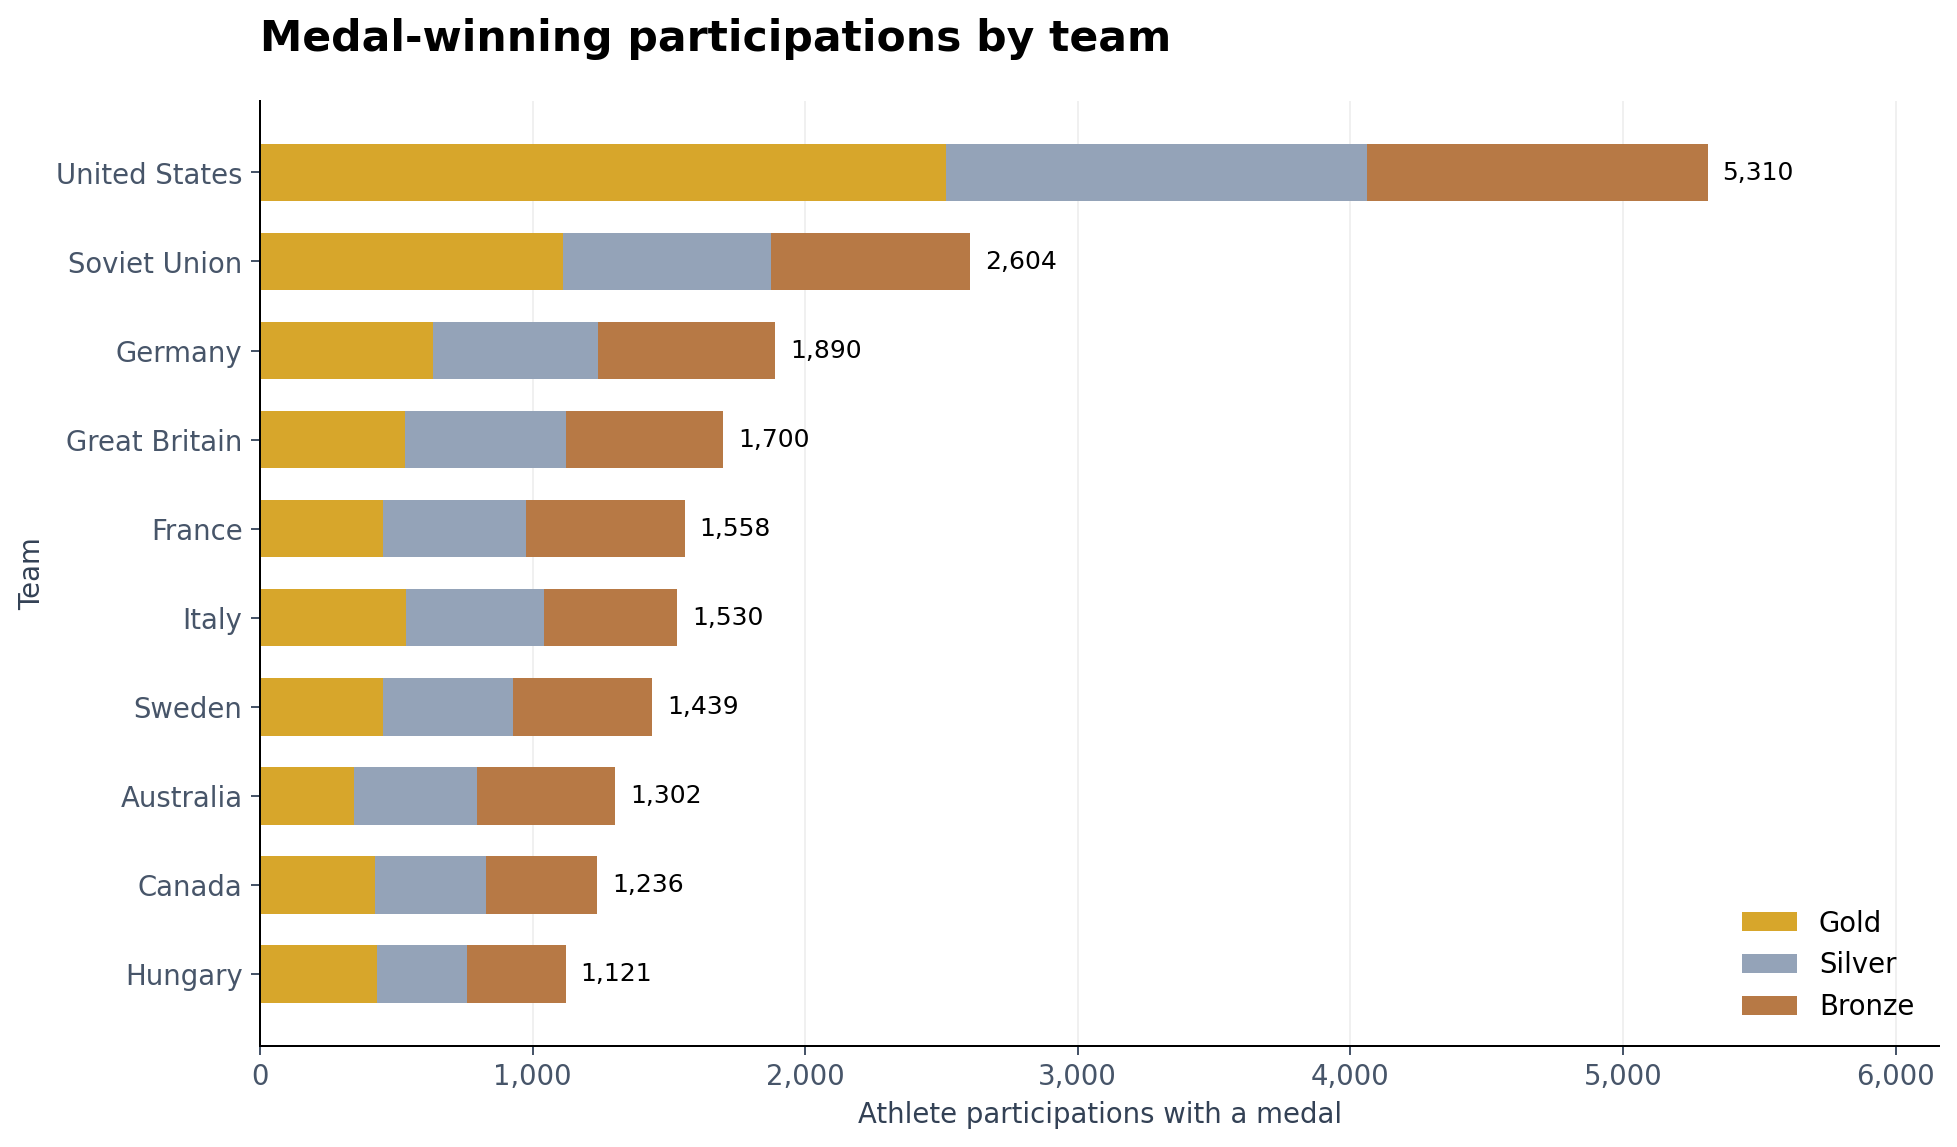

In [ ]:
medallas = leer_csv("medallas_por_equipo.csv")
for fila in medallas:
    fila["Gold"] = int(fila["Gold"])
    fila["Silver"] = int(fila["Silver"])
    fila["Bronze"] = int(fila["Bronze"])
    fila["total"] = fila["Gold"] + fila["Silver"] + fila["Bronze"]

# Elegimos los diez equipos con mayor total y dejamos el primero arriba.
principales = sorted(medallas, key=lambda fila: fila["total"], reverse=True)[:10]
principales.reverse()
equipos = [fila["equipo"] or "Unknown team" for fila in principales]
oro = [fila["Gold"] for fila in principales]
plata = [fila["Silver"] for fila in principales]
bronce = [fila["Bronze"] for fila in principales]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(equipos, oro, color="#d7a62b", label="Gold", height=0.65)
ax.barh(equipos, plata, left=oro, color="#94a3b8", label="Silver", height=0.65)
acumulado = [o + p for o, p in zip(oro, plata)]
ax.barh(equipos, bronce, left=acumulado, color="#b77945", label="Bronze", height=0.65)

for posicion, fila in enumerate(principales):
    ax.text(fila["total"] + 55, posicion, f"{fila['total']:,}", va="center", fontsize=10)

ax.set_title("Medal-winning participations by team", loc="left", pad=20, fontsize=17)
ax.set_xlabel("Athlete participations with a medal")
ax.set_ylabel("Team")
ax.set_xlim(0, max(fila["total"] for fila in principales) * 1.16)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False)
guardar_figura(fig, "medallas_por_equipo.png")

### 9.3. Edad promedio por medalla

Comparamos los promedios de edad de quienes obtuvieron oro, plata o bronce. Usamos la tabla que excluye las edades iguales a cero.

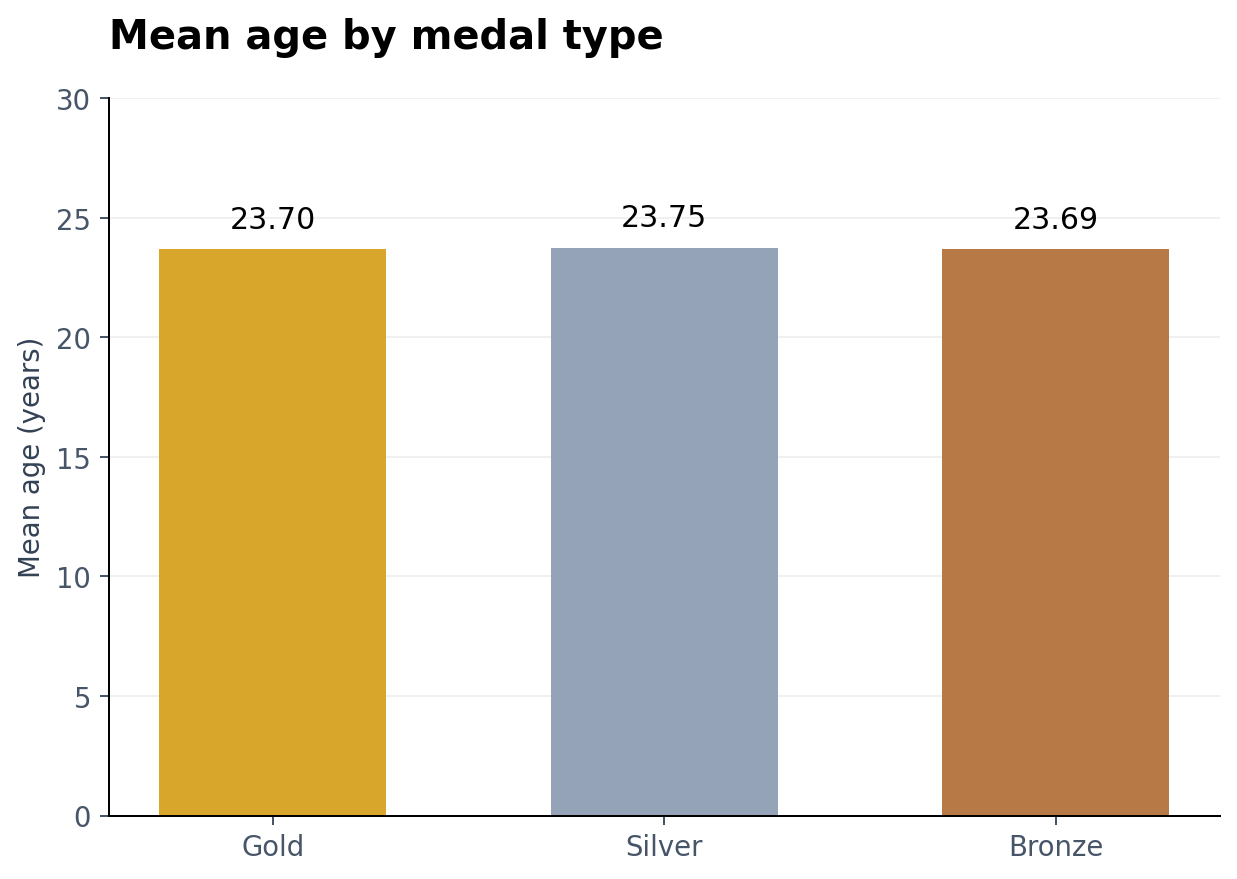

In [ ]:
tabla_edades = leer_csv("edad_por_medalla.csv")
promedios = {fila["medalla"]: float(fila["promedio_edad"]) for fila in tabla_edades}
tipos_medalla = ["Gold", "Silver", "Bronze"]
edades = [promedios[tipo] for tipo in tipos_medalla]

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(tipos_medalla, edades, color=["#d7a62b", "#94a3b8", "#b77945"], width=0.58)
ax.bar_label(barras, labels=[f"{edad:.2f}" for edad in edades], padding=6, fontsize=12)
ax.set_title("Mean age by medal type", loc="left", pad=20, fontsize=16)
ax.set_ylabel("Mean age (years)")
ax.set_ylim(0, 30)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
guardar_figura(fig, "edad_por_medalla.png")

### 9.4. Altura promedio por temporada

Comparamos la altura promedio de las participaciones de Verano e Invierno. Las alturas están expresadas en centímetros.

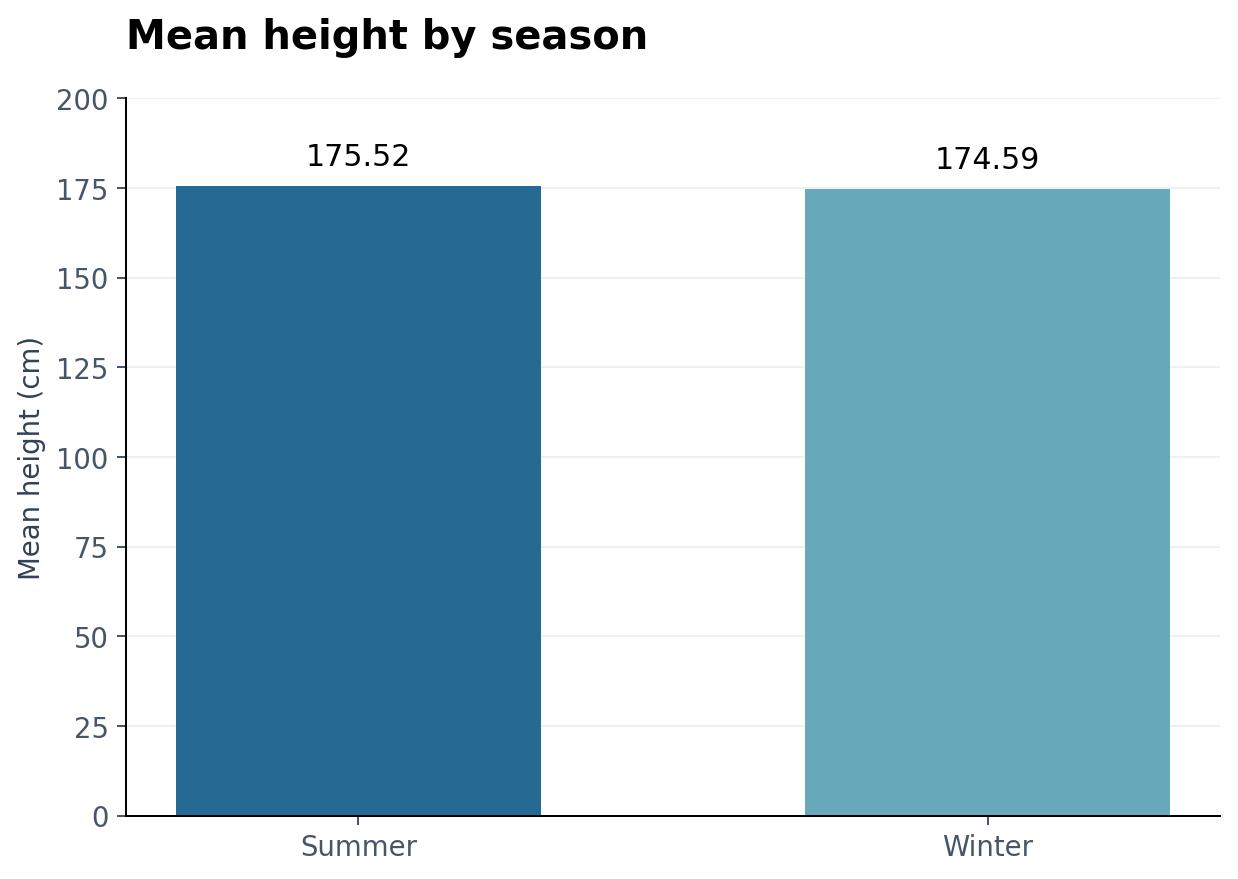

In [ ]:
tabla_alturas = leer_csv("altura_por_temporada.csv")
promedios = {fila["temporada"]: float(fila["promedio_altura"]) for fila in tabla_alturas}
alturas = [promedios["Verano"], promedios["Invierno"]]

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(["Summer", "Winter"], alturas, color=["#246a92", "#69a9bc"], width=0.58)
ax.bar_label(barras, labels=[f"{altura:.2f}" for altura in alturas], padding=6, fontsize=12)
ax.set_title("Mean height by season", loc="left", pad=20, fontsize=16)
ax.set_ylabel("Mean height (cm)")
ax.set_ylim(0, 200)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
guardar_figura(fig, "altura_por_temporada.png")

### 9.5. Edad promedio por sexo

Mostramos el promedio de edad de hombres y mujeres. Cada participación aporta una observación al promedio.

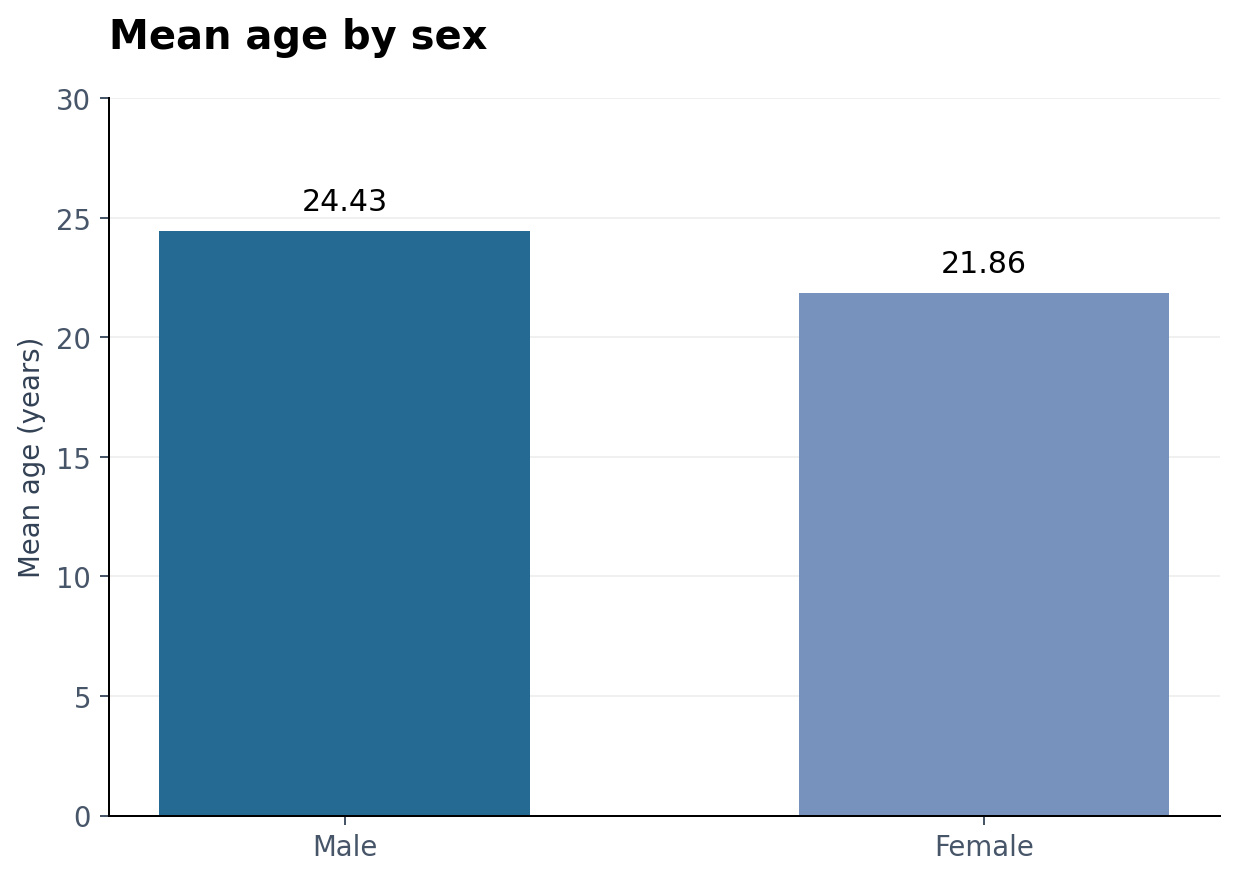

In [ ]:
tabla_sexos = leer_csv("edad_por_sexo.csv")
promedios = {fila["Descripción_sexo"]: float(fila["promedio_edad"]) for fila in tabla_sexos}
edades = [promedios["Hombre"], promedios["Mujer"]]

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(["Male", "Female"], edades, color=["#246a92", "#7892be"], width=0.58)
ax.bar_label(barras, labels=[f"{edad:.2f}" for edad in edades], padding=6, fontsize=12)
ax.set_title("Mean age by sex", loc="left", pad=20, fontsize=16)
ax.set_ylabel("Mean age (years)")
ax.set_ylim(0, 30)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
guardar_figura(fig, "edad_por_sexo.png")

### 9.6. Disponibilidad de los datos

Calculamos qué porcentaje de las participaciones tiene edad, altura o peso sin información. También mostramos los registros sin equipo o evento asociado. Una misma fila puede aparecer en más de una categoría.

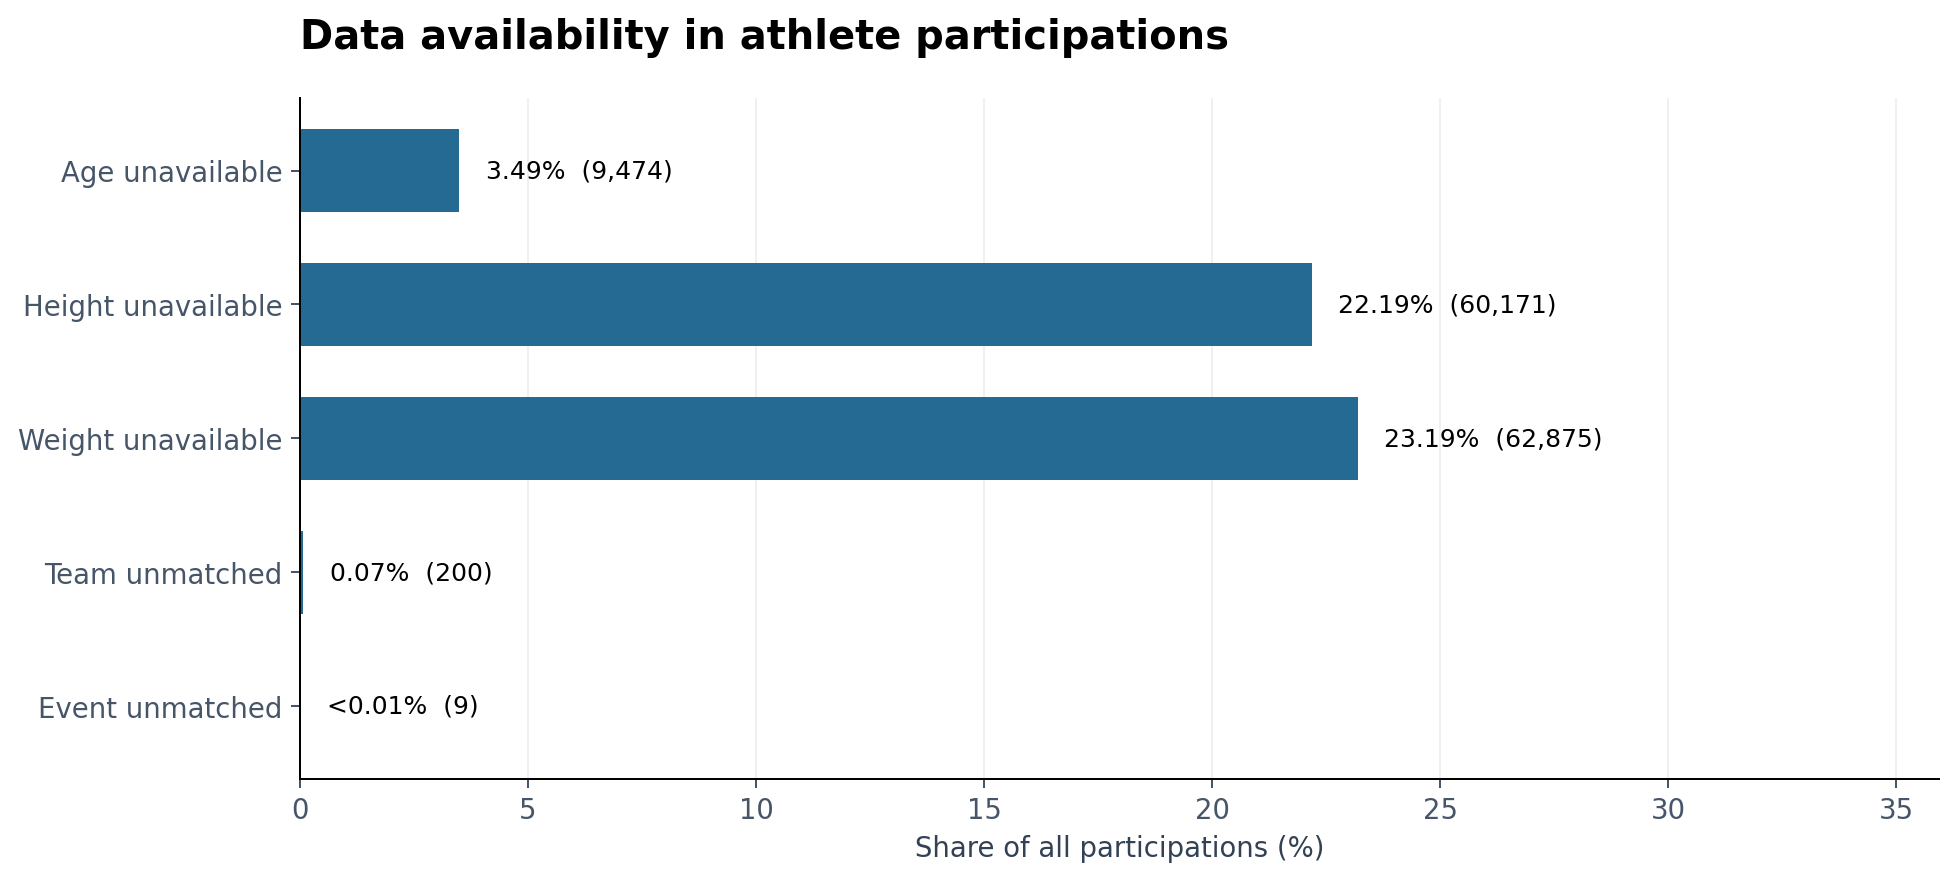

In [ ]:
tabla_calidad = leer_csv("calidad_datos.csv")
conteos = {fila["observacion"]: int(fila["participaciones"]) for fila in tabla_calidad}
resumen = leer_csv("resumen_general.csv")
totales = {fila["indicador"]: int(fila["cantidad"]) for fila in resumen}
total_participaciones = totales["participaciones"]

# Una fila puede tener más de un campo sin información.
claves = ["edad_cero", "altura_cero", "peso_cero", "equipo_sin_nombre", "evento_sin_nombre"]
etiquetas = ['Age unavailable', 'Height unavailable', 'Weight unavailable', 'Team unmatched', 'Event unmatched']
porcentajes = [conteos[clave] / total_participaciones * 100 for clave in claves]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(etiquetas, porcentajes, color="#246a92", height=0.62)
espacio = max(porcentajes) * 0.025
for posicion, clave in enumerate(claves):
    porcentaje = porcentajes[posicion]
    texto = "<0.01%" if 0 < porcentaje < 0.01 else f"{porcentaje:.2f}%"
    ax.text(porcentaje + espacio, posicion, f"{texto}  ({conteos[clave]:,})", va="center", fontsize=10)

ax.invert_yaxis()
ax.set_title("Data availability in athlete participations", loc="left", pad=20, fontsize=16)
ax.set_xlabel("Share of all participations (%)")
ax.set_xlim(0, max(porcentajes) * 1.55)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
guardar_figura(fig, "calidad_datos.png")

### 9.7. Participaciones por edición

Ordenamos las ediciones por año y separamos Verano e Invierno en dos paneles. Así podemos ver los cambios sin mezclar ambas temporadas.

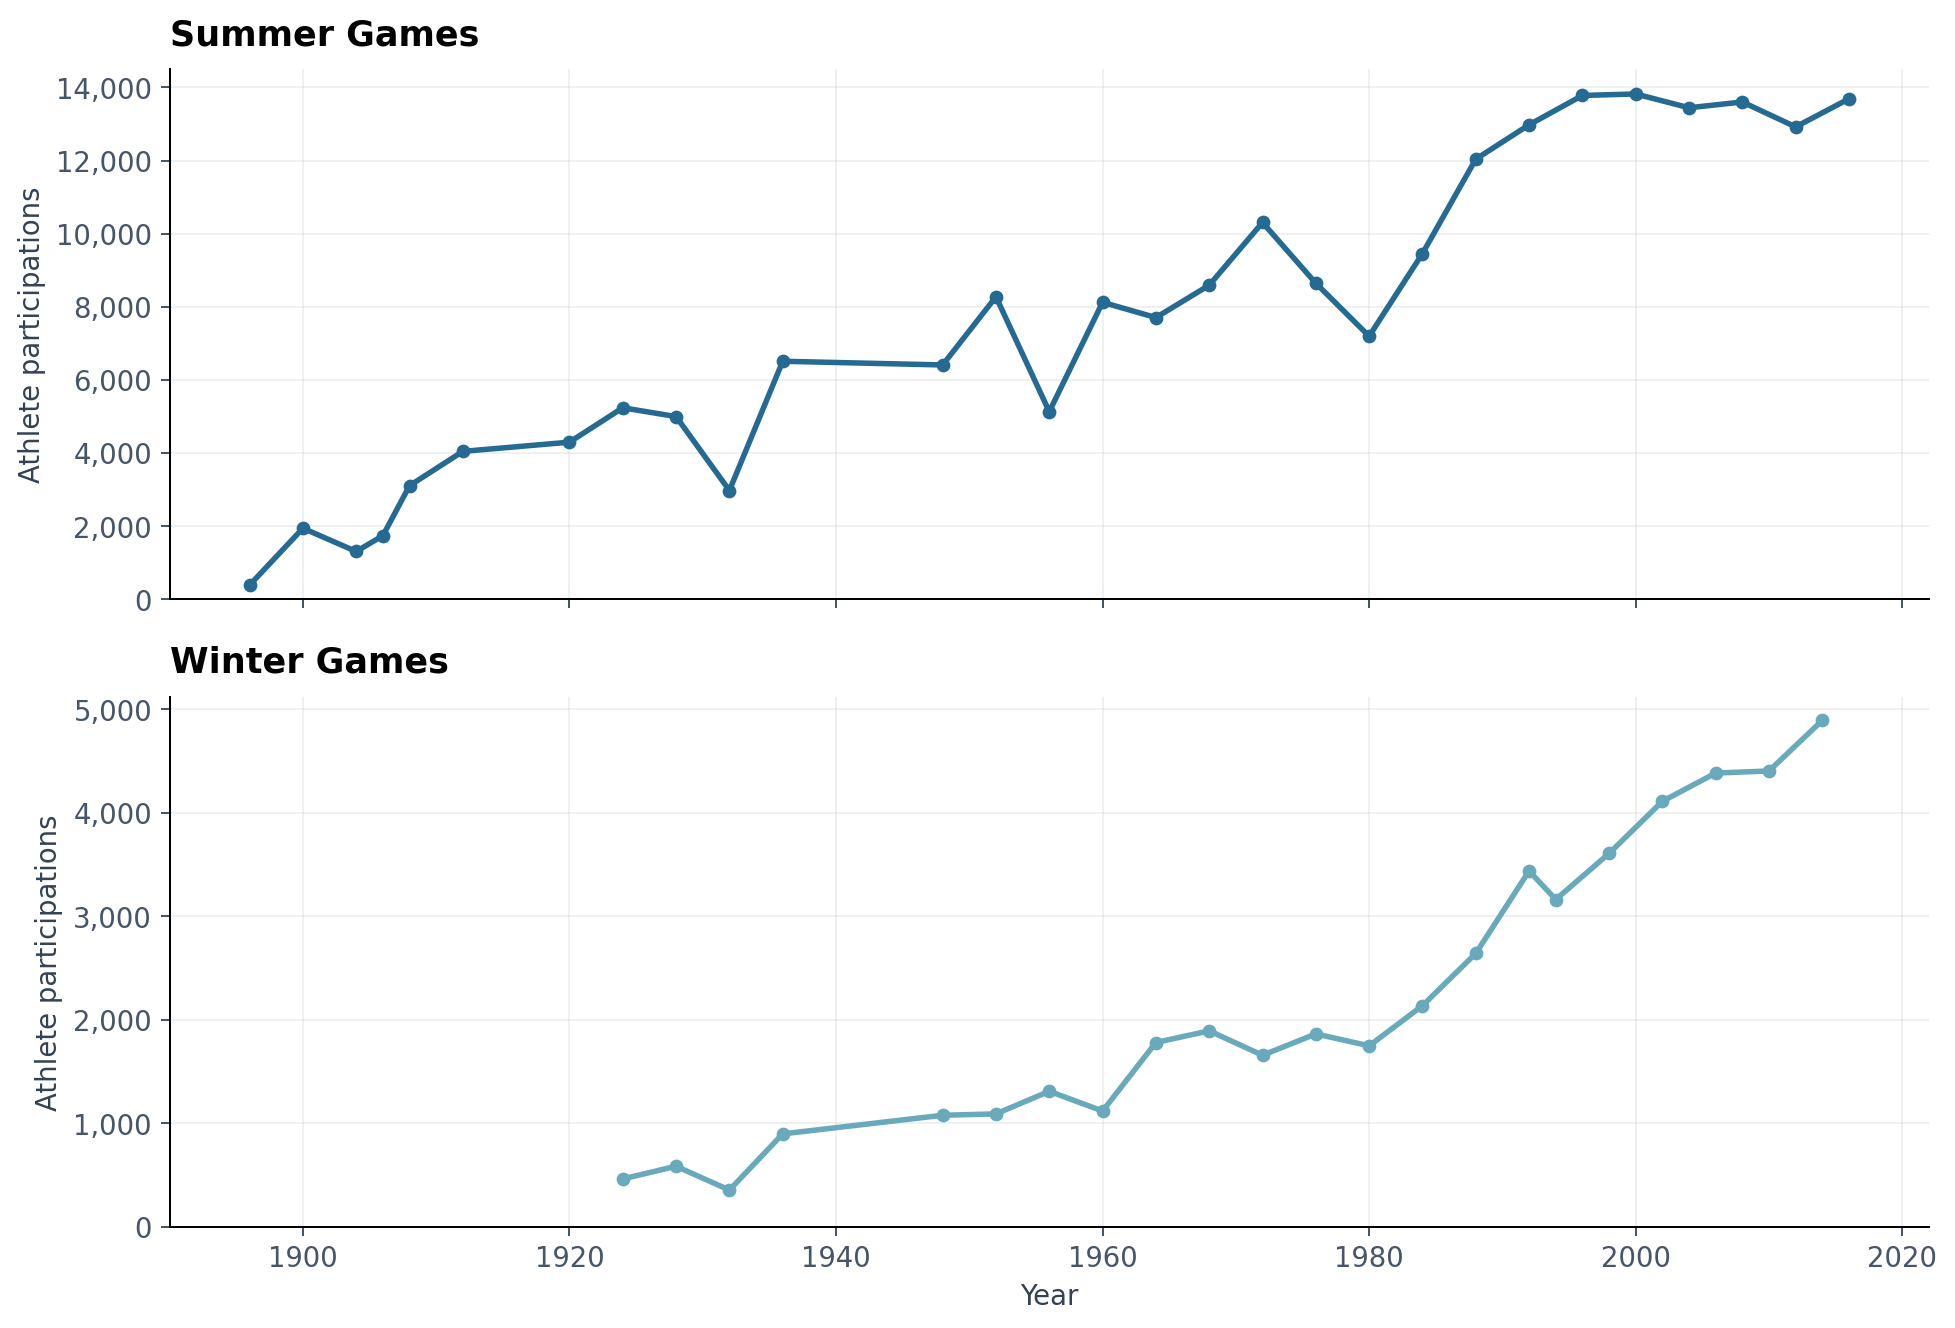

In [ ]:
tabla_ediciones = leer_csv("participaciones_por_edicion.csv")
temporadas = ["Verano", "Invierno"]
titulos = ["Summer Games", "Winter Games"]
colores = ["#246a92", "#69a9bc"]

fig, ejes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for i, temporada in enumerate(temporadas):
    filas = [fila for fila in tabla_ediciones if fila["temporada"] == temporada]
    filas = sorted(filas, key=lambda fila: int(fila["año"]))
    años = [int(fila["año"]) for fila in filas]
    participaciones = [int(fila["participaciones"]) for fila in filas]

    ax = ejes[i]
    ax.plot(años, participaciones, color=colores[i], linewidth=2.2, marker="o", markersize=4.5)
    ax.set_title(titulos[i], loc="left", fontsize=14, pad=10)
    ax.set_ylabel("Athlete participations")
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)

ejes[-1].set_xlabel("Year")
guardar_figura(fig, "participaciones_por_edicion.png")


In [ ]:
print("Resultados guardados en la carpeta resultados/figuras.")


Resultados guardados en la carpeta resultados/figuras.


## 10. Comentarios finales

La unión de los archivos nos permitió trabajar con 271.116 participaciones. Antes de calcular las estadísticas revisamos el separador de resultados, los campos de juegos y una fila de deportistas con una coma adicional.

Las edades promedio por tipo de medalla son muy parecidas. También encontramos promedios de altura cercanos entre Verano e Invierno. Estos resultados describen los registros disponibles y hay que considerar que una persona puede participar en varios eventos o ediciones.

### 10.1. Referencias

- Archivos entregados para el taller.
- [Documentación de PySpark](https://spark.apache.org/docs/latest/api/python/index.html).
- [Documentación de Matplotlib](https://matplotlib.org/stable/).